In [1]:
%pip install bitalino #Descargamos librería de Bitalino
%pip install scipy

#Recordar usar Python 3.10.11


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importamos librerías

import bitalino

import csv

from IPython.display import HTML, display, Javascript

In [22]:
#Configuración del Bitalino

PUERTO = "/dev/tty.bitalino"# Puerto Bluetooth correspondiente al Bitalino

CANAL = 0# A1 = 0, A2 = 1, A3 = 2, etc...

PERIODO = 0.001# (1,0.1,0.01) Cantidad de segundos en que se demora en realizar las mediciones de forma consecutiva desde el inicio del experimento

N = 1000# Número de mediciones realizadas en bloques, cuando se capturen las {N} observaciones serán enviadas al dispotivo receptor para ser
#almacenadas en el .CSV y visualizadas en tiempo real.

#Si {N} = 1 entonces los datos se envian actualizan el CSV y visualizador en tiempo real, si es mayor a 0 entonces se espera a juntar {N}
#observaciones para enviar los datos, actualizar el CSV y el visualizador.

DURACION = 120# Cantidad de segundos en que se demora en realizarse el experimento

In [3]:
with open("visualizador.html", "r", encoding="utf-8") as archivo:
    Visualizador_HTML = archivo.read()

In [4]:
device = bitalino.BITalino(PUERTO)#abre la conexión con el BITalino usando el puerto indicado {PUERTO}

NameError: name 'PUERTO' is not defined

In [6]:
#Procesador sEMG

import numpy as np #Importamos librería para cálculos numéricos
from scipy.signal import butter, iirnotch, sosfilt, sosfilt_zi, tf2sos, welch #Importamos librería para procesamiento de señales

# Clase para procesar señales EMG

class ProcesadorEMG: 
    
    # Inicializa el procesador con la frecuencia de muestreo especificada. 
    def __init__(self, frecuencia_muestreo):
        self.fs = frecuencia_muestreo

        # Verifica que la frecuencia de muestreo sea suficiente para el filtrado de banda EMG.
        if self.fs <= 800:
            raise ValueError(
                "The 25–400 Hz EMG band requires a sampling rate above 800 Hz."
            )

        # Notch de 50 Hz. Q=30 produce un rechazo relativamente estrecho.
        b_notch, a_notch = iirnotch(50.0, Q=30.0, fs=self.fs)
        sos_notch = tf2sos(b_notch, a_notch)

        # Banda EMG, aplicada después del notch.
        sos_bandpass = butter(
            4,
            [25, 400],
            btype="bandpass",
            fs=self.fs,
            output="sos",
        )

        # Las secciones SOS se aplican en cascada: notch y luego bandpass.
        self.sos = np.vstack((sos_notch, sos_bandpass))
        self.estado_filtro = None
        
    # Procesa un bloque de muestras EMG y devuelve el RMS y la frecuencia mediana (MDF).
    def procesar_bloque(self, muestras):
        valores = np.asarray(
            [float(valor) for _, valor in muestras],
            dtype=float,
        )

        if valores.size < 32:
            raise ValueError(
                "The EMG block is too short for reliable spectral analysis."
            )

        # Llevar el estado del filtro hacia adelante para que cada bloque continúe la señal filtrada desde el bloque anterior.
        
        if self.estado_filtro is None:
            self.estado_filtro = sosfilt_zi(self.sos) * valores[0]

        filtrada, self.estado_filtro = sosfilt(
            self.sos,
            valores,
            zi=self.estado_filtro,
        )

        rms = float(np.sqrt(np.mean(filtrada ** 2))) #Calcula el valor RMS de la señal filtrada

        # Welch PSD: segmentos de 0,5 segundos con ventana Hann y solapamiento del 50%.
        
        nperseg = min(valores.size, max(32, round(self.fs * 0.5))) #Ajusta el tamaño del segmento para que sea al menos 32 y no mayor que el tamaño del bloque.
        frecuencias, potencia = welch(
            filtrada, #Señal filtrada para la estimación de la PSD.
            fs=self.fs, #Frecuencia de muestreo para la estimación de la PSD.
            window="hann", #Window Hann para suavizar la señal y reducir el efecto de fuga espectral.
            nperseg=nperseg, #Número de muestras por segmento, ajustado para que sea al menos 32 y no mayor que el tamaño del bloque.
            noverlap=nperseg // 2, #Solapamiento del 50% entre segmentos para mejorar la estimación de la PSD.
            detrend="constant", #Elimina la media de cada segmento para centrarlos alrededor de cero y reducir el sesgo en la estimación de la PSD.
            scaling="density", #Escala la PSD para que represente densidad espectral de potencia (V^2/Hz) en lugar de potencia total, lo que permite comparaciones entre diferentes longitudes de señal y frecuencias.
        )

        # Calcular MDF solo dentro de la banda EMG de interés.
        
        banda = (frecuencias >= 25) & (frecuencias <= 400) #Crea una máscara booleana para seleccionar solo las frecuencias dentro de la banda EMG de interés (25-400 Hz).
        frecuencias_banda = frecuencias[banda] #Aplica la máscara booleana para obtener solo las frecuencias dentro de la banda EMG de interés.
        potencia_banda = potencia[banda] #Aplica la máscara booleana para obtener solo la potencia dentro de la banda EMG de interés.

        potencia_total = float(np.sum(potencia_banda)) #Calcula la potencia total dentro de la banda EMG de interés sumando todas las potencias de frecuencia dentro de la banda.
        if potencia_total <= 0 or frecuencias_banda.size == 0: 
            return rms, float("nan")

        acumulada = np.cumsum(potencia_banda) #Calcula la potencia acumulada dentro de la banda EMG de interés sumando las potencias de frecuencia de manera acumulativa.
        indice = int(np.searchsorted(acumulada, potencia_total / 2)) #Encuentra el índice donde la potencia acumulada alcanza la mitad de la potencia total, lo que corresponde a la frecuencia mediana (MDF).

        if indice == 0:
            mdf = float(frecuencias_banda[0])
        else:
            potencia_previa = acumulada[indice - 1]
            potencia_actual = potencia_banda[indice]

            if potencia_actual <= 0:
                mdf = float(frecuencias_banda[indice])
            else:
                fraccion = (
                    (potencia_total / 2 - potencia_previa) / potencia_actual
                )
                mdf = float(
                    frecuencias_banda[indice - 1]
                    + fraccion
                    * (
                        frecuencias_banda[indice]
                        - frecuencias_banda[indice - 1]
                    )
                )

        return rms, mdf

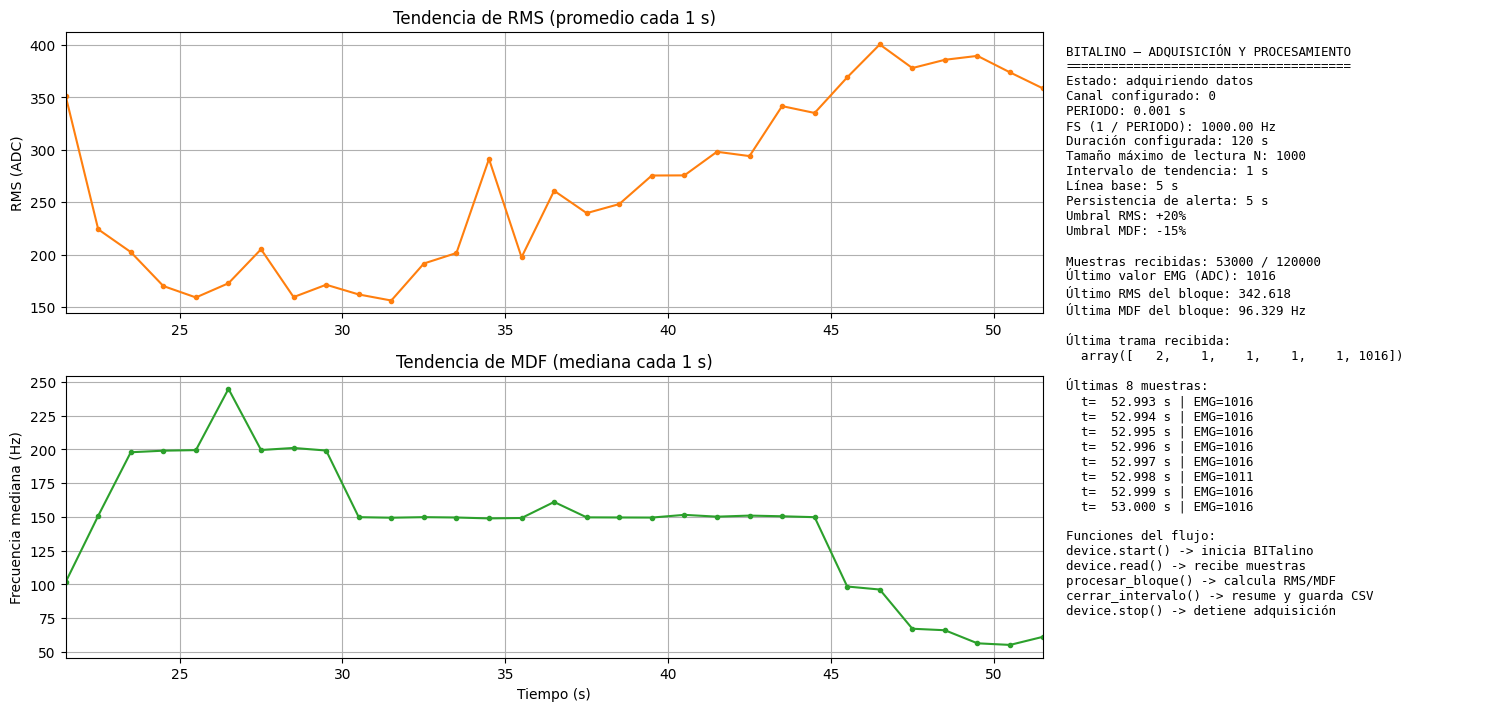

In [ ]:
#Adquisición de sEMG

#Adquisición de tendencia de RMS y MDF a partir de sEMG con alerta de fatiga. 
#El código calcula la tendencia de RMS y MDF a partir de bloques de datos adquiridos desde un dispositivo BITalino 
#Genera alertas si se detecta un patrón consistente de fatiga muscular basado en los umbrales definidos. 
#Los resultados se guardan en un archivo CSV y se visualizan en tiempo real mediante gráficos.

#Importación de librerías necesarias para la adquisición y visualización de datos

import csv
import math
import statistics
import matplotlib.pyplot as plt
from IPython.display import display

#Ajustes de Parámetros de tendencia y alerta de fatiga

FS = 1 / PERIODO # Frecuencia de muestreo
TREND_INTERVAL_S = 1  # Un punto de resumen cada 10 segundos
TREND_WINDOW_S = 30  # Segundos visibles en la gráfica
BASELINE_DURATION_S = 5 # Segundos para calcular la línea base de RMS y MDF
ALERT_PERSISTENCE_S = 5 # Segundos para mantener la alerta de fatiga
RMS_INCREASE_THRESHOLD = 0.20  # 20% por encima de la línea base
MDF_DECREASE_THRESHOLD = 0.15  # 15% por debajo de la línea base

baseline_points_needed = math.ceil(BASELINE_DURATION_S / TREND_INTERVAL_S) #Puntos de tendencia necesarios para calcular la línea base de RMS y MDF
persistence_points_needed = math.ceil(ALERT_PERSISTENCE_S / TREND_INTERVAL_S) #Puntos de tendencia necesarios para mantener la alerta de fatiga

baseline_rms = [] #Valores de RMS para calcular la línea base
baseline_mdf = [] #Valores de MDF para calcular la línea base
fatigue_pattern_streak = 0 #Contador para el patrón de fatiga
fatigue_alerted = False #Bandera para indicar si se ha generado una alerta de fatiga

archivo_features_csv = "EMG_features.csv" 

tiempos_tendencia = [] #Tiempos de tendencia para graficar
rms_tendencia = [] #Valores de RMS para graficar
mdf_tendencia = [] #Valores de MDF para graficar

# Gráfico de tendencias y panel de información del prototipo.
fig = plt.figure(figsize=(15, 7), constrained_layout=True) 
rejilla = fig.add_gridspec(2, 2, width_ratios=[2.2, 1])

# Configuración de subplots para RMS, MDF y panel de información
ax_rms = fig.add_subplot(rejilla[0, 0])
ax_mdf = fig.add_subplot(rejilla[1, 0], sharex=ax_rms)
ax_info = fig.add_subplot(rejilla[:, 1])
ax_info.axis("off")

# Configuración de líneas de tendencia para RMS y MDF
linea_rms, = ax_rms.plot([], [], color="tab:orange", marker=".")
ax_rms.set_title(f"Tendencia de RMS (promedio cada {TREND_INTERVAL_S} s)")
ax_rms.set_ylabel("RMS (ADC)")
ax_rms.set_xlim(0, TREND_WINDOW_S)
ax_rms.grid(True)

# Configuración de línea de tendencia para MDF
linea_mdf, = ax_mdf.plot([], [], color="tab:green", marker=".")
ax_mdf.set_title(f"Tendencia de MDF (mediana cada {TREND_INTERVAL_S} s)")
ax_mdf.set_xlabel("Tiempo (s)")
ax_mdf.set_ylabel("Frecuencia mediana (Hz)")
ax_mdf.set_xlim(0, DURACION)
ax_mdf.grid(True)

# Configuración del panel de información
texto_info = ax_info.text(
    0.02,
    0.98,
    "Esperando datos del BITalino...",
    va="top",
    family="monospace",
    fontsize=9,
)

#Guardar la referencia del gráfico para actualizarlo en tiempo real
grafico = display(fig, display_id=True)
plt.close(fig)

# Valores se mantienen solo para el intervalo de tendencia actual.
bin_tiempos = []
bin_rms = []
bin_mdf = []

# Función para cerrar un intervalo de tendencia, calcular los valores resumidos y actualizar el gráfico y el archivo CSV.
def cerrar_intervalo(escritor_features, archivo_features):
    global fatigue_pattern_streak, fatigue_alerted

    if not bin_tiempos:
        return

    # Calcular los valores resumidos de tendencia para el intervalo actual.
    tiempo_tendencia = statistics.mean(bin_tiempos)
    rms_resumen = statistics.mean(bin_rms)

    # Filtrar valores de MDF válidos (finito) antes de calcular la mediana.
    mdf_validos = [valor for valor in bin_mdf if math.isfinite(valor)]
    mdf_resumen = (
        statistics.median(mdf_validos)
        if mdf_validos
        else float("nan")
    )

    # Usar los primeros puntos de tendencia válidos como línea base.
    if math.isfinite(rms_resumen) and math.isfinite(mdf_resumen):
        if len(baseline_rms) < baseline_points_needed:
            baseline_rms.append(rms_resumen)
            baseline_mdf.append(mdf_resumen)

        elif not fatigue_alerted:
            rms_baseline_level = statistics.median(baseline_rms)
            mdf_baseline_level = statistics.median(baseline_mdf)

            fatigue_pattern = (
                rms_resumen
                >= rms_baseline_level * (1 + RMS_INCREASE_THRESHOLD)
                and mdf_resumen
                <= mdf_baseline_level * (1 - MDF_DECREASE_THRESHOLD)
            )

            if fatigue_pattern:
                fatigue_pattern_streak += 1
            else:
                fatigue_pattern_streak = 0

            if fatigue_pattern_streak >= persistence_points_needed:
                fatigue_alerted = True
                print(
                    "\nPOTENTIAL FATIGUE TREND: RMS is consistently elevated "
                    "and MDF is consistently reduced. Pause the task and "
                    "assess how the muscle feels. This signal is not a "
                    "medical diagnosis."
                )

    # Guardar los valores resumidos de tendencia y actualizar el gráfico.
    tiempos_tendencia.append(tiempo_tendencia)
    rms_tendencia.append(rms_resumen)
    mdf_tendencia.append(mdf_resumen)

    # Guardar solo los valores resumidos de tendencia
    escritor_features.writerow(
        [tiempo_tendencia, rms_resumen, mdf_resumen]
    )
    archivo_features.flush()

    # Actualizar las líneas de tendencia en los gráficos.
    linea_rms.set_data(tiempos_tendencia, rms_tendencia)
    linea_mdf.set_data(tiempos_tendencia, mdf_tendencia)

    # Ajustar los límites de los ejes para mostrar solo los últimos TREND_WINDOW_S segundos.
    ax_rms.relim()
    ax_rms.autoscale_view(scalex=False, scaley=True)
    ax_mdf.relim()
    ax_mdf.autoscale_view(scalex=False, scaley=True)

    # Desplaza la ventana para mantener visibles los últimos TREND_WINDOW_S segundos.
    extremo_derecho = max(TREND_WINDOW_S, tiempo_tendencia)
    extremo_izquierdo = extremo_derecho - TREND_WINDOW_S
    ax_rms.set_xlim(extremo_izquierdo, extremo_derecho)
    ax_mdf.set_xlim(extremo_izquierdo, extremo_derecho)

    # Actualizar el gráfico en tiempo real.
    grafico.update(fig)

    # Limpiar los contenedores de datos del intervalo actual para el próximo bloque.
    bin_tiempos.clear()
    bin_rms.clear()
    bin_mdf.clear()

# Variables de estado de adquisición y procesamiento
n_medicion = 0
adquisicion_iniciada = False
intervalo_actual = None
procesador_emg = ProcesadorEMG(FS)

# Variables para mostrar información en tiempo real
muestras_recientes = [] #Mantiene las últimas 8 muestras para mostrar en el panel de información
ultima_trama = None #Referencia a la última trama recibida del BITalino
ultimo_valor_emg = float("nan") #Último valor EMG recibido del BITalino
ultimo_rms = float("nan") #Último RMS del bloque
ultimo_mdf = float("nan") #Última MDF del bloque

# Función para actualizar el panel de información con los datos más recientes y el estado de adquisición.
def actualizar_panel_adquisicion():
    if muestras_recientes:
        texto_muestras = "\n".join(
            f"  t={tiempo:8.3f} s | EMG={valor}"
            for tiempo, valor in muestras_recientes
        )
    else:
        texto_muestras = "  Todavía no hay muestras."

    texto_trama = repr(ultima_trama)
    if len(texto_trama) > 160:
        texto_trama = texto_trama[:157] + "..."

    # Actualizar el panel de información con los datos más recientes y el estado de adquisición.
    texto_info.set_text(
        "BITALINO — ADQUISICIÓN Y PROCESAMIENTO\n"
        "======================================\n"
        f"Estado: adquiriendo datos\n"
        f"Canal configurado: {CANAL}\n"
        f"PERIODO: {PERIODO} s\n"
        f"FS (1 / PERIODO): {FS:.2f} Hz\n"
        f"Duración configurada: {DURACION} s\n"
        f"Tamaño máximo de lectura N: {N}\n"
        f"Intervalo de tendencia: {TREND_INTERVAL_S} s\n"
        f"Línea base: {BASELINE_DURATION_S} s\n"
        f"Persistencia de alerta: {ALERT_PERSISTENCE_S} s\n"
        f"Umbral RMS: +{RMS_INCREASE_THRESHOLD * 100:.0f}%\n"
        f"Umbral MDF: -{MDF_DECREASE_THRESHOLD * 100:.0f}%\n\n"
        f"Muestras recibidas: {n_medicion} / {n_mediciones_totales}\n"
        f"Último valor EMG (ADC): {ultimo_valor_emg}\n"
        f"Último RMS del bloque: {ultimo_rms:.3f}\n"
        f"Última MDF del bloque: {ultimo_mdf:.3f} Hz\n\n"
        f"Última trama recibida:\n  {texto_trama}\n\n"
        f"Últimas {len(muestras_recientes)} muestras:\n"
        f"{texto_muestras}\n\n"
        "Funciones del flujo:\n"
        "device.start() -> inicia BITalino\n"
        "device.read() -> recibe muestras\n"
        "procesar_bloque() -> calcula RMS/MDF\n"
        "cerrar_intervalo() -> resume y guarda CSV\n"
        "device.stop() -> detiene adquisición"
    )
    # Actualizar el gráfico en tiempo real.
    grafico.update(fig)

#Inicio de la adquisición de datos desde el BITalino y procesamiento en tiempo real.
try:
    with open(
        archivo_features_csv, "w", newline="", encoding="utf-8"
    ) as archivo_features:
        escritor_features = csv.writer(archivo_features)
        escritor_features.writerow(
            ["Time (s)", "Mean RMS (ADC)", "Median MDF (Hz)"]
        )
        archivo_features.flush()

        # Inicia la adquisición de datos desde el BITalino con el período especificado y el canal configurado.
        device.start(1 / PERIODO, [CANAL])
        adquisicion_iniciada = True

        # Calcula el número total de mediciones que se realizarán durante la duración especificada del experimento.
        n_mediciones_totales = int(DURACION / PERIODO)

        # Procesamiento de datos en bloques y actualización de gráficos y CSV en tiempo real.
        while n_medicion < n_mediciones_totales:
            cantidad = min(N, n_mediciones_totales - n_medicion)
            mediciones_bloque = []

            # Leer las muestras del BITalino y procesarlas en tiempo real.
            for muestra in device.read(cantidad):
                n_medicion += 1 #Incrementa el contador de mediciones realizadas
                tiempo = n_medicion * PERIODO #Calcula el tiempo transcurrido desde el inicio del experimento basado en el número de mediciones y el período configurado
                valor = int(muestra[5]) #Valor EMG del canal configurado (A1, A2, etc.) de la muestra recibida del BITalino
                
                ultima_trama = muestra #Referencia a la última trama recibida del BITalino
                ultimo_valor_emg = valor #Último valor EMG recibido del BITalino
                muestras_recientes.append((tiempo, valor)) #Agrega la muestra actual a la lista de muestras recientes para mostrar en el panel de información
                muestras_recientes[:] = muestras_recientes[-8:] #Mantiene solo las últimas 8 muestras para mostrar en el panel de información
                
                mediciones_bloque.append([tiempo, valor]) #Agrega la muestra actual al bloque de mediciones para su posterior procesamiento

            # Procesar el bloque de mediciones si se han recibido datos.
            if mediciones_bloque:
                tiempos_bloque = [
                    tiempo for tiempo, _ in mediciones_bloque
                ]

                rms, mdf = procesador_emg.procesar_bloque(mediciones_bloque) #Calcula el RMS y MDF del bloque de mediciones usando el procesador EMG
                
                ultimo_rms = rms #Último RMS del bloque
                ultimo_mdf = mdf #Última MDF del bloque
                actualizar_panel_adquisicion() #Actualiza el panel de información con los datos más recientes y el estado de adquisición.
                
                tiempo_bloque = statistics.mean(tiempos_bloque) #Calcula el tiempo promedio del bloque de mediciones para asociarlo con los valores de RMS y MDF calculados.
                intervalo = int(tiempo_bloque // TREND_INTERVAL_S) #Calcula el intervalo de tendencia actual basado en el tiempo promedio del bloque y la duración del intervalo de tendencia configurada.

                if (
                    intervalo_actual is not None
                    and intervalo != intervalo_actual
                ):
                    cerrar_intervalo(escritor_features, archivo_features)

                # Guardar los valores del bloque actual para el próximo intervalo de tendencia.
                intervalo_actual = intervalo
                bin_tiempos.append(tiempo_bloque)
                bin_rms.append(rms)
                bin_mdf.append(mdf)

        # Guardar y graficar el intervalo final, incluso si está incompleto
        cerrar_intervalo(escritor_features, archivo_features)

finally:
    if adquisicion_iniciada:
        device.stop()

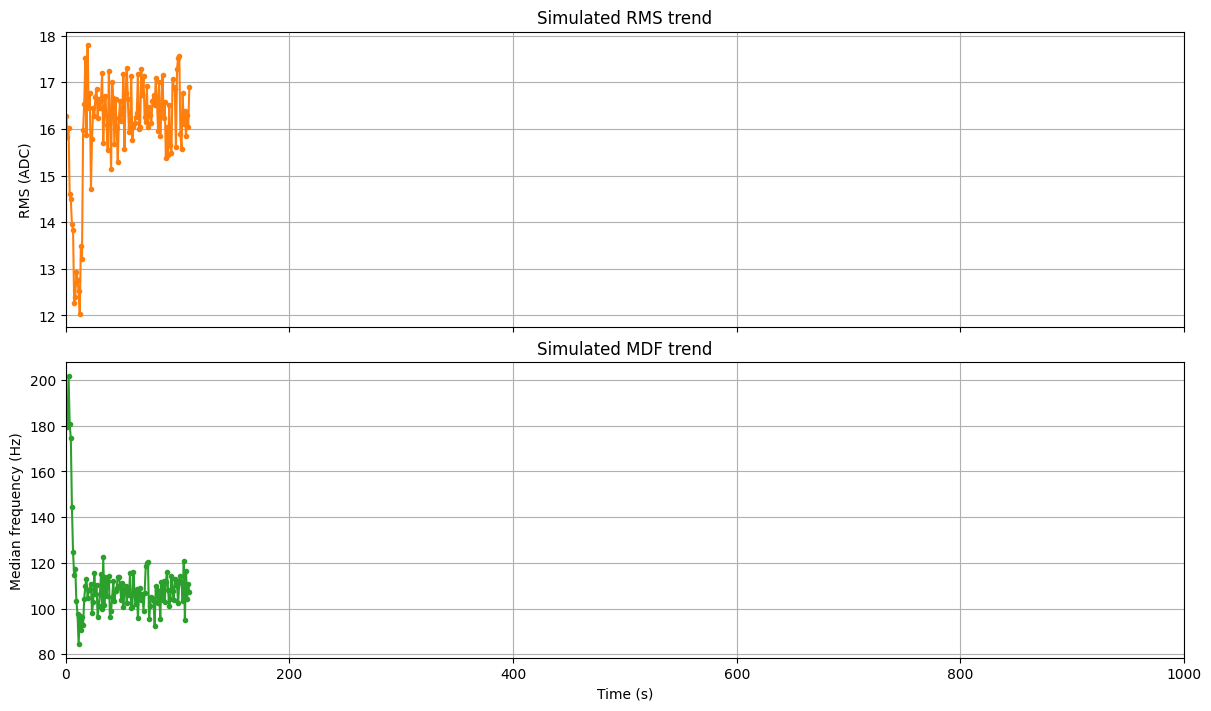

SIMULATED ALERT: the test signal sustained the configured RMS/MDF pattern. This is only a software test, not a medical or physiological conclusion.


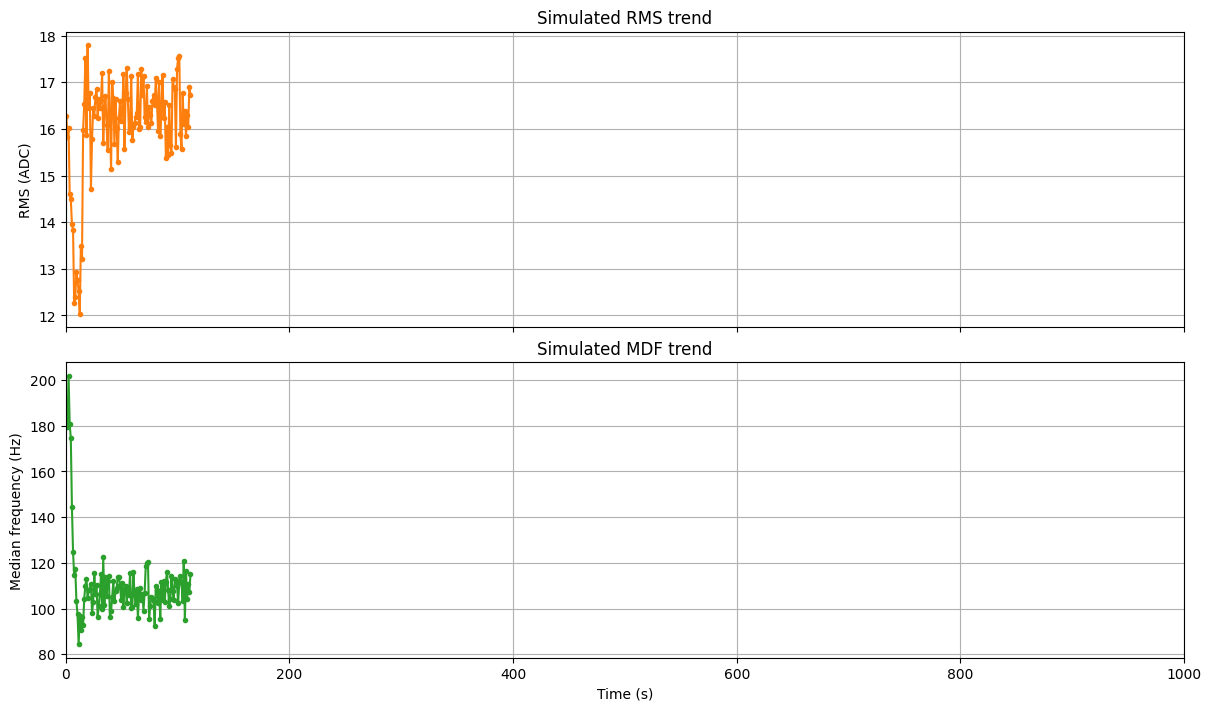

KeyboardInterrupt: 

In [ ]:
# Synthetic EMG trend test — does not connect to BITalino

import csv
import math
import statistics
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import butter, sosfilt, sosfilt_zi

# Choose "normal" to simulate a stable signal, or "fatigue_test"
# to exercise the alert logic with an artificial trend.

SIM_SCENARIO = "fatigue_test"

SIM_DURATION_S = 1000
SIM_TREND_INTERVAL_S = 1
SIM_BASELINE_DURATION_S = 1
SIM_ALERT_PERSISTENCE_S = 1
SIM_RMS_INCREASE_THRESHOLD = 0.05
SIM_MDF_DECREASE_THRESHOLD = 0.01
SIM_OUTPUT_CSV = "EMG_simulated_features.csv"

SIM_FS = 1 / PERIODO

if SIM_FS <= 800:
    raise ValueError(
        "This simulation expects FS > 800 Hz because the EMG processor "
        "uses a 25–400 Hz passband."
    )

if SIM_SCENARIO not in {"normal", "fatigue_test"}:
    raise ValueError("SIM_SCENARIO must be 'normal' or 'fatigue_test'.")

baseline_points_needed = math.ceil(
    SIM_BASELINE_DURATION_S / SIM_TREND_INTERVAL_S
)
persistence_points_needed = math.ceil(
    SIM_ALERT_PERSISTENCE_S / SIM_TREND_INTERVAL_S
)

baseline_rms = []
baseline_mdf = []
fatigue_pattern_streak = 0
fatigue_alerted = False

trend_times = []
trend_rms = []
trend_mdf = []

fig, (ax_rms, ax_mdf) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
)

line_rms, = ax_rms.plot([], [], color="tab:orange", marker=".")
ax_rms.set_title("Simulated RMS trend")
ax_rms.set_ylabel("RMS (ADC)")
ax_rms.set_xlim(0, SIM_DURATION_S)
ax_rms.grid(True)

line_mdf, = ax_mdf.plot([], [], color="tab:green", marker=".")
ax_mdf.set_title("Simulated MDF trend")
ax_mdf.set_xlabel("Time (s)")
ax_mdf.set_ylabel("Median frequency (Hz)")
ax_mdf.set_xlim(0, SIM_DURATION_S)
ax_mdf.grid(True)

plot_handle = display(fig, display_id=True)

# Make two noise-like signals with different spectral distributions.
sos_normal = butter(
    4, [30, 350], btype="bandpass", fs=SIM_FS, output="sos"
)
sos_lower_frequency = butter(
    4, [30, 180], btype="bandpass", fs=SIM_FS, output="sos"
)
state_normal = None
state_lower_frequency = None

def filter_continuously(sos, state, values):
    if state is None:
        state = sosfilt_zi(sos) * values[0]

    filtered, state = sosfilt(sos, values, zi=state)
    return filtered, state

# Use the existing EMG filter/MDF processor from the processor cell.
sim_processor = ProcesadorEMG(SIM_FS)

bin_times = []
bin_rms = []
bin_mdf = []
current_interval = None

rng = np.random.default_rng(42)

def close_simulated_interval(writer, output_file):
    global fatigue_pattern_streak, fatigue_alerted

    if not bin_times:
        return

    time_summary = statistics.mean(bin_times)
    rms_summary = statistics.mean(bin_rms)

    valid_mdf = [value for value in bin_mdf if math.isfinite(value)]
    mdf_summary = (
        statistics.median(valid_mdf) if valid_mdf else float("nan")
    )

    if math.isfinite(rms_summary) and math.isfinite(mdf_summary):
        if len(baseline_rms) < baseline_points_needed:
            baseline_rms.append(rms_summary)
            baseline_mdf.append(mdf_summary)
        elif not fatigue_alerted:
            rms_baseline = statistics.median(baseline_rms)
            mdf_baseline = statistics.median(baseline_mdf)

            pattern_detected = (
                rms_summary >= rms_baseline * (1 + SIM_RMS_INCREASE_THRESHOLD)
                and mdf_summary <= mdf_baseline * (1 - SIM_MDF_DECREASE_THRESHOLD)
            )

            fatigue_pattern_streak = (
                fatigue_pattern_streak + 1 if pattern_detected else 0
            )

            if fatigue_pattern_streak >= persistence_points_needed:
                fatigue_alerted = True
                print(
                    "SIMULATED ALERT: the test signal sustained the configured "
                    "RMS/MDF pattern. This is only a software test, not a "
                    "medical or physiological conclusion."
                )

    trend_times.append(time_summary)
    trend_rms.append(rms_summary)
    trend_mdf.append(mdf_summary)

    writer.writerow([time_summary, rms_summary, mdf_summary])
    output_file.flush()

    line_rms.set_data(trend_times, trend_rms)
    line_mdf.set_data(trend_times, trend_mdf)

    ax_rms.relim()
    ax_rms.autoscale_view(scalex=False, scaley=True)
    ax_mdf.relim()
    ax_mdf.autoscale_view(scalex=False, scaley=True)
    plot_handle.update(fig)

    bin_times.clear()
    bin_rms.clear()
    bin_mdf.clear()


try:
    with open(SIM_OUTPUT_CSV, "w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["Time (s)", "Mean RMS (ADC)", "Median MDF (Hz)"])

        total_samples = int(SIM_DURATION_S * SIM_FS)
        samples_generated = 0

        while samples_generated < total_samples:
            block_size = min(N, total_samples - samples_generated)
            white_noise = rng.normal(0, 1, block_size)

            normal_signal, state_normal = filter_continuously(
                sos_normal, state_normal, white_noise
            )
            lower_signal, state_lower_frequency = filter_continuously(
                sos_lower_frequency, state_lower_frequency, white_noise
            )

            block_start_time = samples_generated / SIM_FS

            if SIM_SCENARIO == "fatigue_test":
                # Artificially raise amplitude and shift spectral energy
                # downward after the baseline period to test alert behavior.
                progression = np.clip(
                    (block_start_time - SIM_BASELINE_DURATION_S) / 15,
                    0,
                    1,
                )
            else:
                progression = 0

            amplitude = 20 * (1 + 0.5 * progression)
            signal = (
                (1 - progression) * normal_signal
                + progression * lower_signal
            )

            adc_values = np.clip(
                np.rint(512 + amplitude * signal), 0, 1023
            ).astype(int)

            times = (
                np.arange(
                    samples_generated + 1,
                    samples_generated + block_size + 1,
                )
                / SIM_FS
            )
            measurements = list(zip(times.tolist(), adc_values.tolist()))

            rms, mdf = sim_processor.procesar_bloque(measurements)
            block_time = statistics.mean(times.tolist())
            interval = int(block_time // SIM_TREND_INTERVAL_S)

            if current_interval is not None and interval != current_interval:
                close_simulated_interval(writer, output_file)

            current_interval = interval
            bin_times.append(block_time)
            bin_rms.append(rms)
            bin_mdf.append(mdf)

            samples_generated += block_size

        close_simulated_interval(writer, output_file)

finally:
    plt.show()

if not fatigue_alerted:
    print(
        f"Simulation complete ({SIM_SCENARIO}). "
        "No alert was triggered by the configured rule."
    )

print(f"Trend summaries saved to: {SIM_OUTPUT_CSV}")